In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import confusion_matrix
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("userclasses_mapped_v2.csv")
df

,type,agentIP,inputPort,outputPort,srcMAC,dstMAC,ethType,inVlan,outVlan,srcIP,...,ipTTL,srcPort,dstPort,tcpFlags,packetSize,payloadSize,skipCount,srcIP_obfuscated,dstIP_obfuscated,userclass
0,FLOW,10.3.99.3,28,0,0cc47aaa3b96,80ee73db5f74,0x0800,110,0,128.171.110.221,...,64,2049,837.0,0x10,1502.0,1480.0,4096.0,317666954423662988337819884758709349115,9658:374d:b657:b424:aa1e:2e2e:4dbf:c5b6,Repository
1,FLOW,10.3.10.202,3,0,3cecefd4d083,ac74b1c0ad87,0x0800,301,0,128.171.226.68,...,53,443,54715.0,0x10,1522.0,1500.0,4096.0,28526535057086749251791746150247753489,29df:d73b:c569:eeec:8656:efda:ca45:5aae,Infrastructure
2,FLOW,10.3.99.3,28,0,3cecefd4d083,ac74b1c0ad87,0x0800,301,0,128.171.226.68,...,53,443,54715.0,0x10,1522.0,1500.0,4096.0,28526535057086749251791746150247753489,29df:d73b:c569:eeec:8656:efda:ca45:5aae,Infrastructure
3,FLOW,10.3.10.202,3,0,3cecefd4d083,ac74b1c0ad87,0x0800,301,0,128.171.226.68,...,53,443,54717.0,0x10,1522.0,1500.0,4096.0,28526535057086749251791746150247753489,29df:d73b:c569:eeec:8656:efda:ca45:5aae,Infrastructure
4,FLOW,10.3.99.3,28,0,0cc47aaa3b96,80ee73db5f74,0x0800,110,0,128.171.110.221,...,64,2049,837.0,0x10,1502.0,1480.0,4096.0,317666954423662988337819884758709349115,9658:374d:b657:b424:aa1e:2e2e:4dbf:c5b6,Repository
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87380,FLOW,10.3.99.3,28,0,0cc47aaa3b96,80ee73db5f74,0x0800,110,0,128.171.110.221,...,64,2049,722.0,0x10,1502.0,1480.0,4096.0,317666954423662988337819884758709349115,9658:374d:b657:b424:aa1e:2e2e:4dbf:c5b6,Repository
87381,FLOW,10.3.99.3,28,0,0cc47aaa3b96,80ee73db5f74,0x0800,110,0,128.171.110.221,...,64,2049,722.0,0x10,1502.0,1480.0,4096.0,317666954423662988337819884758709349115,9658:374d:b657:b424:aa1e:2e2e:4dbf:c5b6,Repository
87382,FLOW,10.3.10.202,3,0,3cecefd4d083,8c8590a01e9c,0x0800,301,0,128.171.73.68,...,63,1194,64690.0,0x10,74.0,52.0,4096.0,236638275706549480470296593420451410312,fce8:19b5:3cbf:5723:ba06:92ac:3c68:fba0,Infrastructure
87383,FLOW,10.3.99.3,28,0,3cecefd4d083,8c8590a01e9c,0x0800,301,0,128.171.73.68,...,63,1194,64690.0,0x18,152.0,130.0,4096.0,236638275706549480470296593420451410312,fce8:19b5:3cbf:5723:ba06:92ac:3c68:fba0,Infrastructure


In [3]:
# Combine Other and Externel into 1 value
df["userclass"] = df["userclass"].replace(["Other", "Externel"], "External")
df["userclass"] = df["userclass"].astype(str).str.strip()

In [4]:
# print(df.shape)
print(sorted(df["userclass"].unique()))

['Admin', 'External', 'Faculty', 'Fiscal', 'IT', 'Infrastructure', 'Manager', 'Observer', 'Other', 'Outreach', 'Phone', 'Printer', 'RemoteControl', 'Repository', 'Researcher', 'Student', 'Visitor']


#### Preprocessing Data

In [5]:
def preprocess_data(df):
    df_processed = df.copy()
    
    X = df_processed.drop('userclass', axis=1)
    y = df_processed['userclass']
    
    cols_to_remove = [
        'agentIP', 'srcMAC', 'dstMAC', 'srcIP', 'dstIP',
        'srcIP_obfuscated', 'dstIP_obfuscated'
    ]
    cols_to_remove = [col for col in cols_to_remove if col in X.columns]
    X = X.drop(cols_to_remove, axis=1)
    
    categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
    
    label_encoders = {}
    for col in categorical_cols:
        le = LabelEncoder()
        X[col] = le.fit_transform(X[col].astype(str))
        label_encoders[col] = le
    
    X = X.fillna(X.median(numeric_only=True))
    
    target_encoder = LabelEncoder()
    y_encoded = target_encoder.fit_transform(y)
    return X, y_encoded, label_encoders, target_encoder

# preprocess_data(df)

In [6]:
X, y, label_encoders, target_encoder = preprocess_data(df)

print(X.shape)
print(len(np.unique(y)))
print(target_encoder.classes_)

(87385, 15)
17
['Admin' 'External' 'Faculty' 'Fiscal' 'IT' 'Infrastructure' 'Manager'
 'Observer' 'Other' 'Outreach' 'Phone' 'Printer' 'RemoteControl'
 'Repository' 'Researcher' 'Student' 'Visitor']


### Train/Test Split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.5,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)
X_train

(43692, 15) (43693, 15)


,type,inputPort,outputPort,ethType,inVlan,outVlan,ipProtocol,ipTos,ipTTL,srcPort,dstPort,tcpFlags,packetSize,payloadSize,skipCount
48936,0,28,0,0,301,0,6,0,63,1194,57914.0,3,1522.0,1500.0,4096.0
60800,0,3,0,0,301,0,6,0,53,443,60290.0,3,1522.0,1500.0,4096.0
78527,0,28,0,0,110,0,6,0,64,2049,797.0,3,1502.0,1480.0,4096.0
71974,0,28,0,0,301,0,6,0,53,443,56327.0,3,1522.0,1500.0,4096.0
14266,0,3,0,0,112,0,6,0,54,443,54336.0,3,1522.0,1500.0,4096.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31436,0,3,0,0,301,0,6,0,61,80,64156.0,3,1522.0,1500.0,4096.0
43042,0,28,0,0,110,0,6,0,64,2049,884.0,3,1502.0,1480.0,4096.0
42108,0,28,0,0,110,0,6,0,64,2049,798.0,3,1502.0,1480.0,4096.0
42973,0,28,0,0,110,0,6,0,64,2049,884.0,3,1502.0,1480.0,4096.0


### Scaling

In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

### Model Training Function

In [9]:
def train_models(X_train, X_test, y_train, y_test, target_encoder):
    models = {
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42),
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42)
    }
    
    results = {}
    
    for name, model in models.items():
        print(f"\nTraining {name}")
        
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        acc = accuracy_score(y_test, y_pred)
        cv = cross_val_score(model, X_train, y_train, cv=5)
        
        results[name] = {
            "model": model,
            "accuracy": acc,
            "cv_mean": cv.mean(),
            "cv_std": cv.std(),
            "predictions": y_pred
        }
        
        print(f"Accuracy: {acc:.4f}")
        print(f"Cross-Validation: {cv.mean():.4f} (+/- {cv.std():.4f})")
    
    best_name = max(results, key=lambda x: results[x]["accuracy"])
    best_model = results[best_name]["model"]
    
    print("\nBest model:", best_name)
    
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        results[best_name]["predictions"],
        labels=np.unique(y_test),
        target_names=target_encoder.classes_
    ))
    
    # Create confusion matrix
    y_pred = results[best_name]["predictions"]
    cm = confusion_matrix(y_test, y_pred)
    cm_df = pd.DataFrame(
        cm,
        index=target_encoder.classes_,
        columns=target_encoder.classes_
    )
    
    # print(f"\nConfusion Matrix of {best_name} (raw counts):")
    # print(cm_df)
    
    # Plot confusion matrix with numbers
    plt.figure(figsize=(12, 10))
    sns.heatmap(
        cm_df, 
        annot=True,           # Show numbers in cells
        fmt='d',              # Format as integers
        cmap="Blues", 
        linewidths=0.5,
        cbar_kws={'label': 'Count'},
        square=True           # Make cells square
    )
    plt.title(f"Confusion Matrix - {best_name}", fontsize=16, pad=20)
    plt.ylabel("True Label", fontsize=12)
    plt.xlabel("Predicted Label", fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    
    return best_model, results, best_name

### Train Models


Training Random Forest
Accuracy: 0.9966
Cross-Validation: 0.9964 (+/- 0.0005)

Training Gradient Boosting
Accuracy: 0.9872
Cross-Validation: 0.9791 (+/- 0.0187)

Training Logistic Regression
Accuracy: 0.9559
Cross-Validation: 0.9564 (+/- 0.0015)

Best model: Random Forest

Classification Report:
                precision    recall  f1-score   support

         Admin       0.95      0.90      0.93       168
      External       0.00      0.00      0.00         1
       Faculty       0.91      0.94      0.93        80
        Fiscal       0.95      0.93      0.94       210
            IT       0.92      0.98      0.95        46
Infrastructure       1.00      1.00      1.00     30190
       Manager       0.89      0.92      0.90       113
      Observer       1.00      1.00      1.00       305
         Other       0.87      0.81      0.84       142
      Outreach       1.00      0.83      0.91         6
         Phone       1.00      0.98      0.99        47
       Printer       0.98    

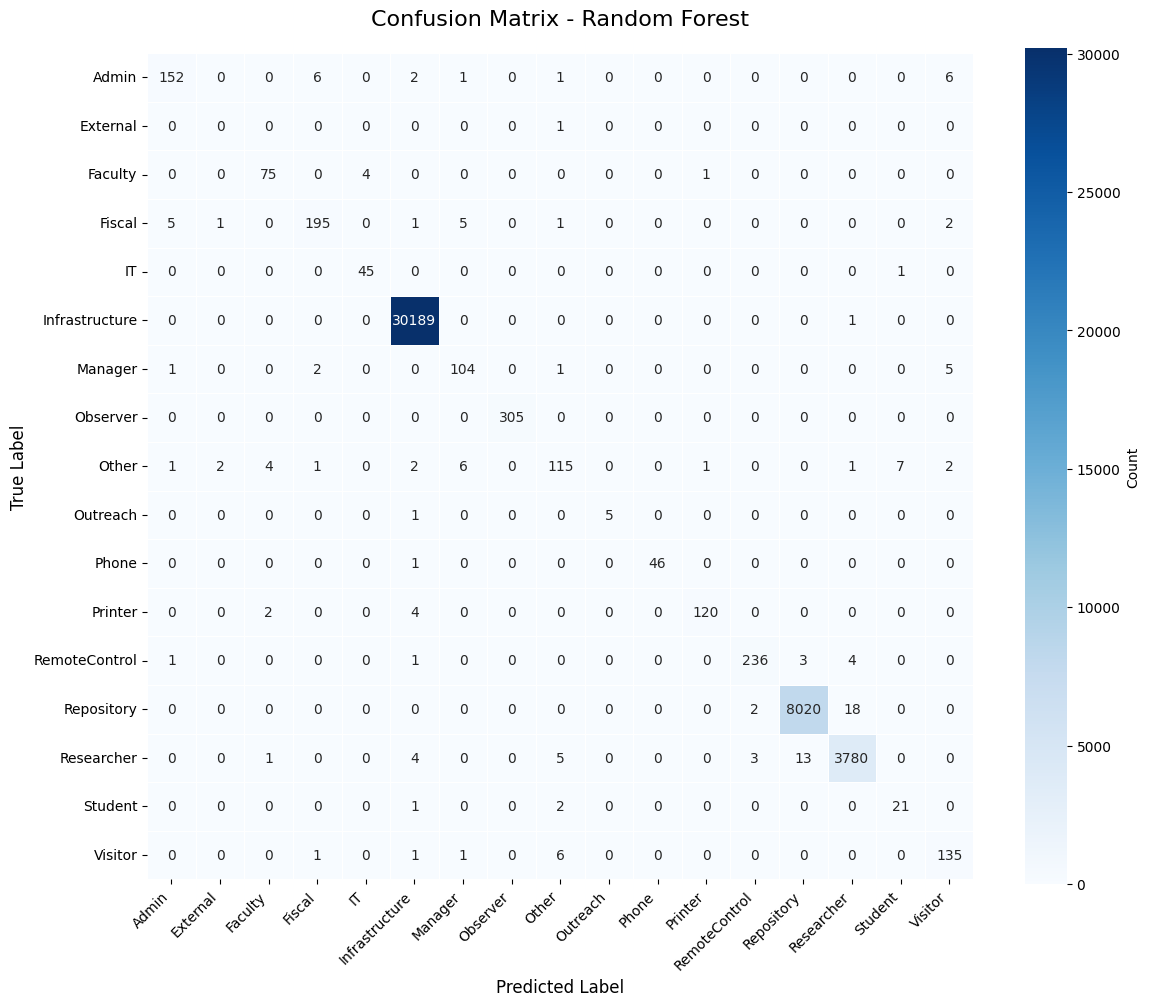

In [10]:
best_model, results, best_model_name = train_models(
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test,
    target_encoder
)

### Summary Comparison

In [69]:
for name, res in results.items():
    print(
        f"{name:20} | "
        f"Acc: {res['accuracy']:.4f} | "
        f"CV: {res['cv_mean']:.4f} (+/- {res['cv_std']:.4f})"
    )

Random Forest        | Acc: 0.9966 | CV: 0.9964 (+/- 0.0005)
Gradient Boosting    | Acc: 0.9872 | CV: 0.9791 (+/- 0.0187)
Logistic Regression  | Acc: 0.9560 | CV: 0.9566 (+/- 0.0017)


In [70]:
print("Train accuracy:", best_model.score(X_train_scaled, y_train))
print("Test accuracy:", best_model.score(X_test_scaled, y_test))

Train accuracy: 0.9999313375446306
Test accuracy: 0.9965669558052778
